# Machine Learning in Python - Project

Due Friday, December 4th 2026, by 4 pm.

**Alejandra Campo Archbold, Theodore Mollano, Lorena Peral Sánchez, Rachel Rodríguez José**

## Setup

In [15]:
# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn
from scipy.cluster import hierarchy
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV

# warnings library
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load data
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

# Introduction

The Scottish Government asked us to provide insights into river water levels in Scotland. The data contain the daily average, minimum and maximum water levels recorded at 392 river monitoring stations from October 2014 to October 2026. For each station we also know its county and its coordinates. In this report, we answer two questions:

1. **Clustering:** Cluster the river level monitoring stations.
2. **Regression:** For each station, predict the water levels for each day in September, October,
and November 2026.

**Approach**

-

**Key findings**

-


# Exploratory Data Analysis and Feature Engineering

### Understanding data

In [3]:
print("df_locs:", df_locs.shape, "| missing values:", df_locs.isna().sum().sum())
print("df_avg, df_min, df_max:", df_avg.shape, df_min.shape, df_max.shape)
df_avg.iloc[:3, :6]

df_locs: (392, 5) | missing values: 0
df_avg, df_min, df_max: (392, 4382) (392, 4382) (392, 4382)


,County,Station_Name,Observation_ID,05/10/2014,06/10/2014,07/10/2014
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,NaN,NaN,NaN
1,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,NaN,NaN,NaN
2,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,NaN,NaN,NaN


 >  `df_locs` has the county, name, observation ID and coordinates of each of the 392 stations, with no missing values. The three level files have 3 text columns plus one column per day (the dates are column names), and the first days are mostly empty because most stations start later.

In [20]:
dates = pd.to_datetime(df_avg.columns[3:], format="%d/%m/%Y")
missing_days = pd.date_range(dates.min(), dates.max()).difference(dates)
print(f"From {dates.min().date()} to {dates.max().date()}: {len(dates)} dates in the files, {len(missing_days)} days missing")
missing_days

From 2014-10-05 to 2026-10-08: 4379 dates in the files, 8 days missing


DatetimeIndex(['2014-10-11', '2014-10-12', '2014-11-26', '2015-04-17',
               '2015-04-22', '2015-05-03', '2015-05-26', '2016-04-06'],
              dtype='datetime64[ns]', freq=None)

> Eight days are missing. We reshape the three level files to one row per day and one column per station, and add the missing days as empty rows, so the calendar has no gaps.

In [5]:
def to_daily(df):
    # one row per calendar day, one column per station
    d = df.drop(columns=["County", "Station_Name"]).set_index("Observation_ID").T
    d.index = pd.to_datetime(d.index, format="%d/%m/%Y")
    return d.sort_index().asfreq("D")  # adds the missing days as empty rows

avg_ = to_daily(df_avg)
min_ = to_daily(df_min).reindex_like(avg_)  # same days and station order as avg_
max_ = to_daily(df_max).reindex_like(avg_)
locs = df_locs.set_index("Observation_ID").loc[avg_.columns]  # station info in the same order

print(f"Daily tables: {avg_.shape[0]} days x {avg_.shape[1]} stations")

Daily tables: 4387 days x 392 stations


### Data cleaning

In [6]:
print("Duplicated IDs:", df_locs["Observation_ID"].duplicated().sum())
print("Average outside [min, max]:", ((avg_ < min_) | (avg_ > max_)).sum().sum())

# station names used by two different IDs
counts = locs["Station_Name"].value_counts()
dup_names = counts[counts > 1].index
print("Names that appear twice:", len(dup_names))
print("IDs with 'tidal-level':", locs.index.str.contains("tidal-level").sum())

Duplicated IDs: 0
Average outside [min, max]: 0
Names that appear twice: 12
IDs with 'tidal-level': 12


> No ID is duplicated and the daily average is always between the daily minimum and maximum. However, 12 station names appear twice and 12 IDs contain "tidal-level"

In [7]:
locs["tide_gauge"] = locs["Station_Name"].isin(dup_names)
print("Tide gauge series:", locs["tide_gauge"].sum())

Tide gauge series: 24


### Outliers

In [8]:
avg_.stack().describe()

count    1.190691e+06
mean     3.883943e+00
std      1.185799e+03
min     -1.904754e+05
25%      2.920000e-01
50%      4.770000e-01
75%      7.630000e-01
max      1.000000e+06
dtype: float64

> The extremes (1,000,000 m and -190,475 m) are error codes, and each gauge has its own zero (the median is about 0.5 m, but one station is always near 30 m), so one fixed threshold for all stations does not work. With band = q99 - q01 of each station, a value is an outlier if it is more than 3 bands above q99 or below q01: percentiles are not distorted by the error codes, and the wide band keeps real floods.

In [9]:
def outliers(d, k=3):
    # True if more than k bands above q99 or below q01 of each station
    q01, q99 = d.quantile(0.01), d.quantile(0.99)
    band = q99 - q01
    return (d > q99 + k * band) | (d < q01 - k * band)

# if any of the three files is an outlier, that station-day becomes NaN in all three
bad = outliers(avg_) | outliers(min_) | outliers(max_)
avg_c, min_c, max_c = avg_.mask(bad), min_.mask(bad), max_.mask(bad)

n_bad = bad.sum().sum()
print(f"Values set to NaN: {n_bad} ({n_bad / avg_.count().sum():.2%} of the readings)")
print("Stations affected:", bad.any().sum())

Values set to NaN: 379 (0.03% of the readings)
Stations affected: 102


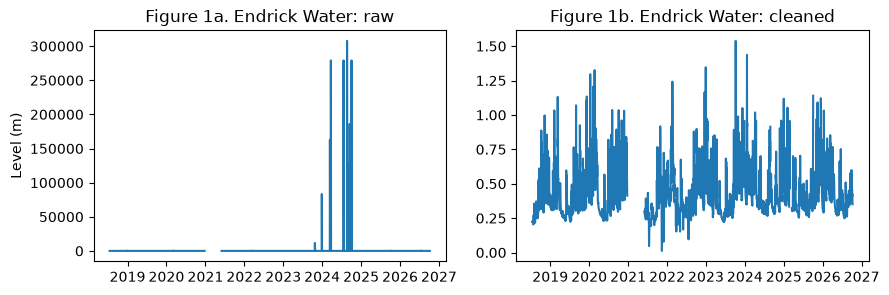

In [19]:
# example: one station before and after cleaning
s = "stirling-and-falkirk__endrick-water-graystone-bridge__obs1"
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(avg_[s])
ax[0].set(title="Figure 1a. Endrick Water: raw", ylabel="Level (m)")
ax[1].plot(avg_c[s])
ax[1].set(title="Figure 1b. Endrick Water: cleaned")
plt.show()

> Only a tiny share of the readings is removed (output above), and Figure 1 shows that the error spikes disappear while the real signal, including the high winter levels, stays. We do not drop any rows: the day still exists, only the wrong reading becomes NaN.

### Missing values

Missing values: 30.8%
Days with all stations: 0


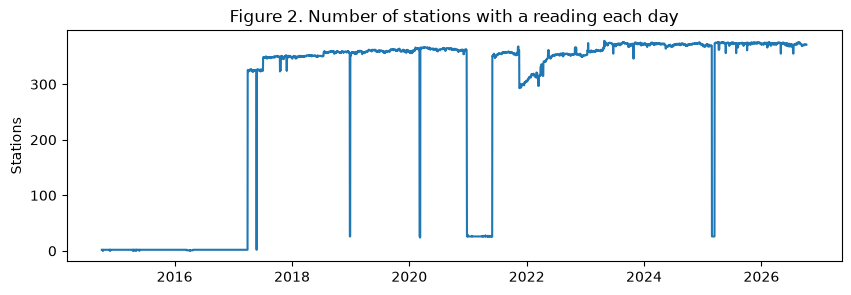

In [18]:
cover = avg_c.notna().sum(axis=1)  # stations with a reading each day
print(f"Missing values: {avg_c.isna().mean().mean():.1%}")
print("Days with all stations:", (cover == avg_c.shape[1]).sum())

plt.figure(figsize=(10, 3))
plt.plot(cover)
plt.title("Figure 2. Number of stations with a reading each day")
plt.ylabel("Stations")
plt.show()

> About 31% of the values are missing, and Figure 2 shows that they come in blocks of time: few stations report before 2017, and many stop for a few months in early 2021. No day has all stations and imputing would invent months of levels, so we keep every station and day and only leave out missing rows when fitting each model.

### Clean data set

For modelling we build one table with one row per station and day, with the three cleaned levels, the date parts and the station information.

In [12]:
levels = {"level_avg": avg_c, "level_min": min_c, "level_max": max_c}
data = (pd.DataFrame({name: d.unstack() for name, d in levels.items()})
          .rename_axis(["Observation_ID", "date"]).reset_index()
          .join(locs[["County", "Station_Name", "Latitude", "Longitude", "tide_gauge"]], on="Observation_ID"))
data = data.assign(year=data["date"].dt.year, month=data["date"].dt.month, day=data["date"].dt.day)

data = data[["County", "Station_Name", "Observation_ID", "date", "year", "month", "day",
             "level_avg", "level_min", "level_max", "Latitude", "Longitude", "tide_gauge"]]

print(f"{len(data):,} rows (stations x days), {data.shape[1]} columns")
data.dropna(subset=["level_avg"]).head(3)  # first rows with a reading

1,719,704 rows (stations x days), 13 columns


,County,Station_Name,Observation_ID,date,year,month,day,level_avg,level_min,level_max,Latitude,Longitude,tide_gauge
908,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,2017-03-31,2017,3,31,0.221,0.219,0.223,57.424758,-2.802015,False
909,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,2017-04-01,2017,4,1,0.221,0.216,0.231,57.424758,-2.802015,False
910,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,2017-04-02,2017,4,2,0.220,0.214,0.228,57.424758,-2.802015,False


## Regression feature engineering
### Training and testing sets

We train with data until 31 August 2026 and forecast September to November 2026.

In [13]:
TRAIN_END = pd.Timestamp("2026-08-31")
TEST_START = pd.Timestamp("2026-09-01")

print("Training days:", len(avg_[:TRAIN_END]))
print("Test days:", len(avg_[TEST_START:]))

Training days: 4349
Test days: 38


# Model Fitting and Tuning

*In this section you should detail and motivate your choice of model and describe the process used to refine, tune, and fit that model. You are encouraged to explore different models but you should NOT include a detailed narrative or code of all of these attempts. At most this section should very briefly mention the methods explored and why they were rejected - most of your effort should go into describing the final model you are using and your process for tuning and validating it.*

*This section should include the full implementation of your final model, including all necessary validation. All displayed figures should be described and referenced in the text.*

*You should also include a baseline model of your choice and provide a comparison of your model with the baseline model on the test data. You should briefly describe the baseline model considered.*

**We want to develop a model to predict the weather a week in advance**

>The standard approach is regression:
>
> - Mask the average, minimum and maximum levels.
> - Split the data into training and test sets with `TimeSeriesSplit`, which is designed for time series data.
> - Use lagged readings so model only sees data $k$ days ago. This way it learns to predict the future.
> - Apply `StandardScaler` to all numeric features.
> - Map each date onto one of 365 days and encode with `OneHotEncoder`.
> - Scale the year, latitude and longitude with `StandardScaler`.
>
> How well it performs is best compared against a baseline model 
> The persistence model just predicts the water level it sees on any given day -  "if it rains 10 inches today, it will rain 10 inches all of this week."
>
> We train seven models: one for each $k \in \{1, \dots, 7\}$. 

In [ ]:
import pandas as pd

In [57]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import r2_score, mean_absolute_error

In [ ]:
reg_results = []

reg_base = data.dropna(subset=["level_avg", "level_min", "level_max"]).copy()
reg_base["day_of_year"] = pd.to_datetime(reg_base["date"]).dt.dayofyear.clip(upper=365)
reg_base["tide_gauge"] = reg_base["tide_gauge"].astype(int)

for h in range(1, 8): #loop over seven days in the week, for each, train a regresison model
    '''
    TimeSeriesSplit with 80/20 training/test. 
    StandardScalar for all numeric features, with exception of the days with a OneHotEncoder
    '''

    #lagged data
    reg_lag_cols = [f"level_avg_lag{h}", f"level_min_lag{h}", f"level_max_lag{h}"]
    reg_lagged = reg_base[["Observation_ID", "date", "level_avg", "level_min", "level_max"]].copy()
    reg_lagged["date"] = reg_lagged["date"] + pd.Timedelta(days=h)
    reg_lagged.columns = ["Observation_ID", "date"] + reg_lag_cols
    reg_h_data = reg_base.merge(reg_lagged, on=["Observation_ID", "date"]).sort_values("date")

    reg_features = reg_h_data[["day_of_year", "year", "Latitude", "Longitude", "tide_gauge"] + reg_lag_cols]
    reg_target = reg_h_data["level_avg"]

    #train/test split
    reg_train_idx, reg_test_idx = list(TimeSeriesSplit(n_splits=4).split(reg_features))[-1]
    reg_features_train, reg_features_test = reg_features.iloc[reg_train_idx], reg_features.iloc[reg_test_idx]
    reg_target_train, reg_target_test = reg_target.iloc[reg_train_idx], reg_target.iloc[reg_test_idx]

    reg_preprocess = make_column_transformer(
        (OneHotEncoder(handle_unknown="ignore"), ["day_of_year"]),
        (StandardScaler(), ["year", "Latitude", "Longitude"] + reg_lag_cols),
        ("passthrough", ["tide_gauge"]),
    )
    reg_model = make_pipeline(reg_preprocess, RidgeCV(alphas=[0.01, 0.1, 1, 10, 100]))
    reg_model.fit(reg_features_train, reg_target_train)
    print(f"Model trained for {h} day(s) ahead", flush=True)

    reg_pred = reg_model.predict(reg_features_test)
    reg_persist = reg_features_test[f"level_avg_lag{h}"]
    reg_results.append({
        "days_ahead": h,
        "model_R2": r2_score(reg_target_test, reg_pred),
        "persistence_R2": r2_score(reg_target_test, reg_persist),
    })
reg_results = pd.DataFrame(reg_results).set_index("days_ahead")

In [66]:
print(reg_results)

            model_R2  persistence_R2
days_ahead                          
1           0.990459        0.990320
2           0.983901        0.983669
3           0.979715        0.979263
4           0.976898        0.976383
5           0.974106        0.973535
6           0.971990        0.971352
7           0.970205        0.969490


Notes for improvement-
>
>The model slightly outperforms the persistence baseline.
>
> Can we do better? Can we choose a better $\alpha$ for ridge regression? How to use dimensionality reduction

# Interpretation, Discussion & Conclusions

*In this section you should provide a general overview of your final clustering and of your final supervised learning model, its performance, and reliability. You should discuss what the implications of your models are in terms of the included features, estimated parameters and relationships, predictive performance, and anything else you think is relevant.*

*This should be written with a target audience of a government official, who understands the monitoring of river levels but may only have university level mathematics (not necessarily postgraduate statistics or machine learning). Your goal should be to highlight to this audience how your model can useful. You should also discuss potential limitations or directions of future improvement of your model.*

*Finally, you should include recommendations on factors that may influence the classification of flood events OR the prediction of future water levels (depending on which question you are answering), which may be useful for the government officials to improve their understanding of floods or water level forecasting, and potentially assist in the development of effective river management and interventions.*

*Keep in mind that a negative result, i.e. a model that does not work well predictively, that is well explained and justified in terms of why it failed will likely receive higher marks than a model with strong predictive performance but with poor or incorrect explanations / justifications.*

# Generative AI statement

*Include a statement on if and how generative AI was used in the project and report.*

# References

*Include a list of all references cited in the text.*

In [ ]:
# Run the following to render to PDF
!jupyter nbconvert --to pdf project.ipynb

[NbConvertApp] WARNING | pattern 'project.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
--execute
    Exe